# 06 — Trees and gradient boosting from scratch (XGBoost-style)

**Goal:** close the open items from the 2026-10-26 log: a tree as a *function* (not an array), the closed-form leaf
value, `g = p − y` and `h = p(1 − p)` for log-loss, and `w* = −G / (H + λ)`. At the end your boosting model matches
scikit-learn's `GradientBoostingClassifier` to 6 decimals.
**Time:** ~4 h. **Level:** 2 / 5. Same rules as notebook 00.

**On paper first (20 min, no code):**
1. For squared loss, the best constant on a leaf is ___. For a split, the SSE reduction is ___.
2. For log-loss `ℓ(y, F) = log(1 + e^F) − yF`: `g = ∂ℓ/∂F = ___`, `h = ∂²ℓ/∂F² = ___`.
3. Second-order Taylor of `Σ ℓ(yᵢ, Fᵢ + w)` over a leaf, plus `½λw²`: minimiser `w* = ___`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(0)

def check(cond, msg):
    assert cond, "❌ " + msg
    print("✅", msg)

## Part 1 — The best split on one feature

Sort by `x`. For every cut between two **distinct** consecutive values, compute the SSE reduction
`SSE(parent) − SSE(left) − SSE(right)`. Doing it in O(n) after the sort uses cumulative sums:
`SSE = Σy² − (Σy)²/n`. The threshold is the midpoint between the two values.

In [2]:
def brute_force_split(x, y, min_leaf=1):
    """Slow reference, O(n^2). Use it only to check yours."""
    best = (-np.inf, None)
    sse = lambda v: ((v - v.mean()) ** 2).sum() if len(v) else 0.0
    xs = np.unique(x)
    for a, b in zip(xs[:-1], xs[1:]):
        t = (a + b) / 2; L, R = y[x <= t], y[x > t]
        if len(L) < min_leaf or len(R) < min_leaf:
            continue
        gain = sse(y) - sse(L) - sse(R)
        if gain > best[0]:
            best = (gain, t)
    return best

def best_split_1d(x, y, min_leaf=1):
    """Vectorised: returns (gain, threshold), or (-inf, None) if no valid split.
    Steps: argsort; cumsum of y and y**2; for cut after position i (left = first i+1 sorted points), compute
    SSE_left + SSE_right; mask cuts where x_sorted[i] == x_sorted[i+1] or a side has < min_leaf points."""
    o = np.argsort(x, kind="stable"); xs, ys = x[o], y[o]; n = len(y)
    cs, cs2 = np.cumsum(ys), np.cumsum(ys ** 2)
    nl = np.arange(1, n)                                   # left sizes for cuts 0..n-2
    sl, sl2 = cs[:-1], cs2[:-1]
    sr, sr2 = cs[-1] - sl, cs2[-1] - sl2
    nr = n - nl
    child = (sl2 - sl ** 2 / nl) + (sr2 - sr ** 2 / nr)
    parent = cs2[-1] - cs[-1] ** 2 / n
    gain = parent - child
    valid = (xs[:-1] < xs[1:]) & (nl >= min_leaf) & (nr >= min_leaf)
    if not valid.any():
        return -np.inf, None
    gain = np.where(valid, gain, -np.inf); i = int(np.argmax(gain))
    return gain[i], (xs[i] + xs[i + 1]) / 2

**✍️ Predict before running.** Hand example: x = [1, 2, 3, 4, 5, 6], y = [1, 1, 1, 5, 5, 6]. Where is the best threshold and what is the gain? Compute it on paper.

> Prediction:
>
> Confidence: [1] / [2] / [3]

In [3]:
x6 = np.array([1, 2, 3, 4, 5, 6.]); y6 = np.array([1, 1, 1, 5, 5, 6.])
g, t = best_split_1d(x6, y6)
check(t == 3.5 and np.isclose(g, brute_force_split(x6, y6)[0]), f"hand example: threshold {t}, gain {g:.3f}")
for trial in range(20):
    x = np.round(rng.normal(size=60), 1); y = rng.normal(size=60); ml = int(rng.integers(1, 8))
    gb, tb = brute_force_split(x, y, ml); gv, tv = best_split_1d(x, y, ml)
    assert np.isclose(gb, gv) and tb == tv, f"❌ mismatch on random trial {trial} (min_leaf={ml}, ties in x)"
print("✅ matches brute force on 20 random cases with ties and min_leaf")

✅ hand example: threshold 3.5, gain 28.167
✅ matches brute force on 20 random cases with ties and min_leaf


## Part 2 — A regression tree

Nodes live in a flat list `self.nodes`. A leaf is `{"value": v}`; an internal node is
`{"feature": j, "threshold": t, "left": i, "right": k}` (indices into the list). Go left if `x[j] <= t`.

Stopping rules (same as scikit-learn): stop at `max_depth`; don't split a node with fewer than `2 * min_leaf`
samples; don't split if the best gain is `<= 0` or no valid split exists. Across features, take the largest gain
(first feature wins ties).

In [4]:
class RegressionTree:
    def __init__(self, max_depth=3, min_leaf=1):
        self.max_depth, self.min_leaf = max_depth, min_leaf

    def fit(self, X, y):
        self.nodes = []
        self._build(X, y, np.arange(len(y)), depth=0)
        return self

    def _build(self, X, y, idx, depth):
        """Append the node for samples idx to self.nodes, recursively; return its index in self.nodes.
        Tip: append a placeholder first to reserve your index, then fill it after building the children."""
        me = len(self.nodes); self.nodes.append({"value": y[idx].mean()})
        if depth >= self.max_depth or len(idx) < 2 * self.min_leaf:
            return me
        best = (-np.inf, None, None)
        for j in range(X.shape[1]):
            g, t = best_split_1d(X[idx, j], y[idx], self.min_leaf)
            if g > best[0]:
                best = (g, j, t)
        g, j, t = best
        if t is None or g <= 1e-12:
            return me
        m = X[idx, j] <= t
        left = self._build(X, y, idx[m], depth + 1)
        right = self._build(X, y, idx[~m], depth + 1)
        self.nodes[me] = {"feature": j, "threshold": t, "left": left, "right": right}
        return me

    def apply(self, X):
        """Index (in self.nodes) of the leaf each row of X falls into. Returns (n,) ints."""
        out = np.empty(len(X), dtype=int)
        for r, x in enumerate(X):
            i = 0
            while "value" not in self.nodes[i]:
                nd = self.nodes[i]
                i = nd["left"] if x[nd["feature"]] <= nd["threshold"] else nd["right"]
            out[r] = i
        return out

    def predict(self, X):
        return np.array([self.nodes[i]["value"] for i in self.apply(X)])

In [5]:
from sklearn.tree import DecisionTreeRegressor

Xr = rng.normal(size=(400, 5)); yr = np.sin(2 * Xr[:, 0]) + Xr[:, 1] ** 2 + 0.3 * rng.normal(size=400)
Xr_te = rng.normal(size=(200, 5))
for depth, ml in [(1, 1), (3, 5), (6, 10)]:
    mine = RegressionTree(depth, ml).fit(Xr, yr)
    ref = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=ml, random_state=0).fit(Xr, yr)
    check(np.allclose(mine.predict(Xr_te), ref.predict(Xr_te)), f"depth={depth}, min_leaf={ml}: matches sklearn")

✅ depth=1, min_leaf=1: matches sklearn
✅ depth=3, min_leaf=5: matches sklearn
✅ depth=6, min_leaf=10: matches sklearn


**✍️ Predict before running.** Plot train and test MSE for max_depth 1..12 (test = new data from the same function). At which depth does test MSE bottom out? What does train MSE do?

> Prediction:
>
> Confidence: [1] / [2] / [3]

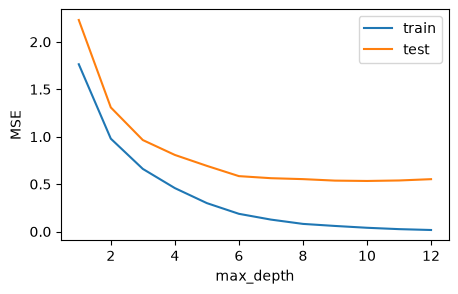

✅ train keeps falling while test turns back up


In [6]:
Xr_te2 = rng.normal(size=(1000, 5)); yr_te2 = np.sin(2 * Xr_te2[:, 0]) + Xr_te2[:, 1] ** 2 + 0.3 * rng.normal(size=1000)
tr, te = [], []
for dpt in range(1, 13):
    m = RegressionTree(dpt, 1).fit(Xr, yr)
    tr.append(np.mean((m.predict(Xr) - yr) ** 2)); te.append(np.mean((m.predict(Xr_te2) - yr_te2) ** 2))
plt.figure(figsize=(5, 3)); plt.plot(range(1, 13), tr, label="train"); plt.plot(range(1, 13), te, label="test")
plt.xlabel("max_depth"); plt.ylabel("MSE"); plt.legend(); plt.show()
check(tr[-1] < 0.25 * tr[0] and te[-1] > min(te), "train keeps falling while test turns back up")

## Part 3 — Gradient boosting for log-loss with Newton leaves

Algorithm (this is what both scikit-learn's `GradientBoostingClassifier` and, with λ and γ, XGBoost do):

1. `F₀ = log(p̄ / (1 − p̄))` for every sample, where `p̄` is the training prevalence.
2. For m = 1..M: `p = σ(F)`, `g = p − y`, `h = p(1 − p)`.
   Fit a regression tree to the **negative gradient** `−g` (structure only).
   Replace each leaf's value by the Newton step `w = −Σg / (Σh + λ)` over the training samples in that leaf.
   `F ← F + η · tree(x)`.

Store the trees; `decision_function(X)` returns `F(X)` (log-odds).

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class GBMClassifier:
    def __init__(self, n_trees=50, lr=0.1, max_depth=3, min_leaf=1, lam=0.0):
        self.n_trees, self.lr, self.max_depth, self.min_leaf, self.lam = n_trees, lr, max_depth, min_leaf, lam

    def fit(self, X, y, X_val=None, y_val=None):
        """Fit; if validation data is given, record self.val_loss (mean log-loss after each tree)."""
        self.trees, self.val_loss = [], []
        pbar = y.mean(); self.F0 = np.log(pbar / (1 - pbar))
        F = np.full(len(y), self.F0)
        Fv = None if X_val is None else np.full(len(y_val), self.F0)
        for _ in range(self.n_trees):
            p = sigmoid(F); g = p - y; h = p * (1 - p)
            tree = RegressionTree(self.max_depth, self.min_leaf).fit(X, -g)
            leaves = tree.apply(X)
            for leaf in np.unique(leaves):
                m = leaves == leaf
                tree.nodes[leaf]["value"] = -g[m].sum() / (h[m].sum() + self.lam)
            F += self.lr * tree.predict(X)
            self.trees.append(tree)
            if Fv is not None:
                Fv += self.lr * tree.predict(X_val)
                self.val_loss.append(np.mean(np.logaddexp(0, Fv) - y_val * Fv))
        return self

    def decision_function(self, X):
        return self.F0 + self.lr * sum(t.predict(X) for t in self.trees)

    def predict_proba(self, X):
        return sigmoid(self.decision_function(X))

In [8]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.datasets import make_classification
from sklearn.metrics import roc_auc_score

Xb, yb = make_classification(n_samples=1500, n_features=8, n_informative=5, flip_y=0.05, random_state=1)
Xb_tr, Xb_va, Xb_te = Xb[:800], Xb[800:1100], Xb[1100:]
yb_tr, yb_va, yb_te = yb[:800], yb[800:1100], yb[1100:]

mine = GBMClassifier(n_trees=30, lr=0.1, max_depth=3, min_leaf=5).fit(Xb_tr, yb_tr)
ref = GradientBoostingClassifier(n_estimators=30, learning_rate=0.1, max_depth=3, min_samples_leaf=5,
                                 random_state=0).fit(Xb_tr, yb_tr)
diff = np.abs(mine.decision_function(Xb_tr) - ref.decision_function(Xb_tr)).max()
print(f"max |F_mine - F_sklearn| on the training set = {diff:.2e}")
check(diff < 1e-6, "your boosting matches sklearn's GradientBoostingClassifier on the training set")
auc_m, auc_r = roc_auc_score(yb_te, mine.decision_function(Xb_te)), roc_auc_score(yb_te, ref.decision_function(Xb_te))
print(f"test AUROC: yours {auc_m:.4f} | sklearn {auc_r:.4f}")
check(abs(auc_m - auc_r) < 0.01, "same test AUROC")

max |F_mine - F_sklearn| on the training set = 1.55e-15
✅ your boosting matches sklearn's GradientBoostingClassifier on the training set


test AUROC: yours 0.9086 | sklearn 0.9081
✅ same test AUROC


Why compare on the training set only? When two features give **exactly the same partition** of a small node, the
gains tie; sklearn breaks ties by a random feature order, you by "first feature". Same training predictions, slightly
different thresholds, so new points can land differently.

If the training check fails, the usual culprits are: `F₀` not set to the log-odds, leaf values left as the mean of
`−g` instead of the Newton step, or the learning rate applied twice.

**✍️ Predict before running.** Validation log-loss vs number of trees (up to 200) for lr = 1.0, 0.3, 0.1, 0.03, depth 3. Which reaches the lowest minimum? Which overfits fastest? Where is the minimum for lr = 0.03?

> Prediction:
>
> Confidence: [1] / [2] / [3]

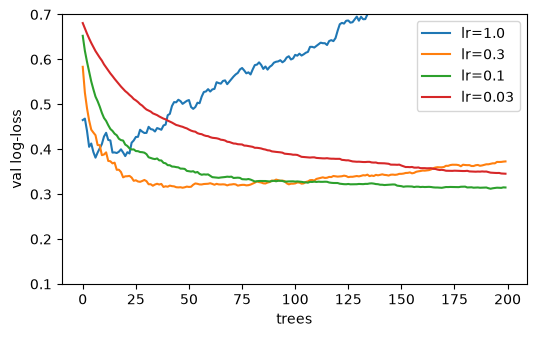

lr=1.0   best val loss 0.381 at 7 trees
lr=0.3   best val loss 0.314 at 48 trees
lr=0.1   best val loss 0.312 at 193 trees
lr=0.03  best val loss 0.345 at 200 trees
✅ high learning rate reaches its best much earlier, then overfits


In [9]:
plt.figure(figsize=(6, 3.5))
best = {}
for lr in [1.0, 0.3, 0.1, 0.03]:
    m = GBMClassifier(n_trees=200, lr=lr, max_depth=3, min_leaf=5).fit(Xb_tr, yb_tr, Xb_va, yb_va)
    best[lr] = (min(m.val_loss), int(np.argmin(m.val_loss)) + 1)
    plt.plot(m.val_loss, label=f"lr={lr}")
plt.ylim(0.1, 0.7); plt.xlabel("trees"); plt.ylabel("val log-loss"); plt.legend(); plt.show()
for lr, (l, k) in best.items():
    print(f"lr={lr:<5} best val loss {l:.3f} at {k} trees")
check(best[1.0][1] < best[0.1][1], "high learning rate reaches its best much earlier, then overfits")

`λ` shrinks every leaf toward 0, more strongly when `Σh` is small (few samples, or confident predictions with
`p(1 − p) ≈ 0`). Try `lam` in `[0, 1, 10, 100]` at `lr = 1.0` and look at the minimum of the validation curve.
No check here — write what you see in the log.

In [10]:
# your experiment with lam here

## Debrief → `learning/LOG.md`

1. `g`, `h` for log-loss and `w* = −G/(H + λ)`, derived without notes. Gain formula for a split, with `γ`.
2. Why "fit the negative gradient" generalises "fit the residuals".
3. Learning rate vs number of trees: what you predicted vs what happened.
4. **Still shaky.** If you hit the "tree treated as an array" bug again, say so — it was on the list last time.